# Radiation-induced hypothyroidism: leakage-safe nested-CV analysis
Front-end notebook for the `thyroid_rihp` package. The original notebook (`thyroid-6292026.ipynb`) is preserved unchanged; see `reports/AUDIT_REPORT.md` for what was fixed.

**All results below are internal (nested, repeated, stratified) cross-validation on 115 patients / 27 events. There is no external validation.**

In [1]:
import os, sys, warnings
os.environ.setdefault('OMP_NUM_THREADS', '1')
ROOT = os.path.abspath('..')
sys.path.insert(0, ROOT)
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from thyroid_rihp.config import load_config, resolve
from thyroid_rihp.data import load_dataset, feature_group_combinations, combo_name
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
cfg = load_config(os.path.join(ROOT, 'config', 'config.yaml'))
cfg['paths']['data_dir'] = os.path.join(ROOT, 'data'); cfg['paths']['output_dir'] = os.path.join(ROOT, 'outputs')
RUN = resolve(cfg, 'output_dir') / 'main'

## 1. Data validation

In [2]:
ds = load_dataset(cfg)
v = {k: x for k, x in ds.validation.items() if k != 'files'}
pd.Series({k: v[k] for k in ['n_patients','n_positive','n_negative','prevalence','n_features_per_group',
          'label_consistent_across_files','ids_identical_across_files','outcome_sorted_by_row_order',
          'rows_sharing_identical_name_in_CB','name_mismatch_ids_vs_CB']})

n_patients                                                                       115
n_positive                                                                        27
n_negative                                                                        88
prevalence                                                                  0.234783
n_features_per_group                      {'CB': 5, 'DVH': 12, 'RF': 107, 'DF': 107}
label_consistent_across_files                                                   True
ids_identical_across_files                                                      True
outcome_sorted_by_row_order                                                     True
rows_sharing_identical_name_in_CB                             [P107, P112, P56, P78]
name_mismatch_ids_vs_CB              {'CB': [], 'DVH': [], 'RF': [], 'DF': ['P109']}
dtype: object

In [3]:
labels = cfg['data']['group_labels']
pd.DataFrame({'configuration': [combo_name(c, labels) for c in feature_group_combinations()]})

,configuration
0,CBs
1,DVH
2,CT RFs
3,DFs
4,CBs+DVH
5,CBs+CT RFs
6,CBs+DFs
7,DVH+CT RFs
8,DVH+DFs
9,CT RFs+DFs


## 2. Run the analysis (already executed; use the command line for the full run)
```bash
python scripts/run_nested_cv.py --run-name main
python scripts/make_figures.py --run-name main
```
A quick end-to-end check: `python scripts/run_nested_cv.py --run-name smoke --smoke`.

## 3. Headline results (pre-specified primary model: L2 logistic regression with class weighting)

In [4]:
summ = pd.read_csv(RUN / 'tables' / 'metrics_summary.csv')
pm, ps = cfg['models']['primary_model'], cfg['models']['primary_strategy']
prim = summ[(summ.model == pm) & (summ.strategy == ps)]
cols = ['config','roc_auc','roc_auc_ci_low','roc_auc_ci_high','pr_auc','sensitivity','specificity','precision','f1',
        'balanced_accuracy','brier','calibration_slope','mean_n_features']
prim[cols].round(3).reset_index(drop=True)

,config,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,sensitivity,specificity,precision,f1,balanced_accuracy,brier,calibration_slope,mean_n_features
0,CBs,0.357,0.283,0.436,0.184,0.333,0.455,0.156,0.212,0.394,0.269,-7.684,2.0
1,DVH,0.953,0.907,0.985,0.865,0.889,0.883,0.713,0.787,0.886,0.119,2.542,2.0
2,CT RFs,0.413,0.328,0.499,0.201,0.370,0.538,0.190,0.240,0.454,0.267,-1.256,2.0
3,DFs,0.897,0.830,0.947,0.736,0.802,0.856,0.631,0.706,0.829,0.143,1.652,2.0
4,CBs+DVH,0.924,0.867,0.970,0.820,0.827,0.920,0.761,0.792,0.874,0.112,1.428,2.0
5,CBs+CT RFs,0.390,0.314,0.461,0.197,0.420,0.432,0.183,0.252,0.426,0.280,-2.952,2.0
6,CBs+DFs,0.897,0.830,0.947,0.736,0.802,0.852,0.625,0.702,0.827,0.143,1.652,2.0
7,DVH+CT RFs,0.942,0.893,0.978,0.782,0.864,0.864,0.672,0.752,0.864,0.095,1.033,2.0
8,DVH+DFs,0.946,0.902,0.979,0.843,0.852,0.871,0.678,0.753,0.862,0.093,1.159,2.0
9,CT RFs+DFs,0.897,0.830,0.948,0.736,0.802,0.852,0.625,0.702,0.827,0.143,1.648,2.0


## 4. All models and imbalance strategies (sensitivity analysis)

In [5]:
summ.pivot_table(index='config', columns=['model','strategy'], values='roc_auc').round(3)

model               logreg_enet                  logreg_l2               random_forest                 svm_linear              
strategy           class_weight   none  smote class_weight   none  smote  class_weight   none  smote class_weight   none  smote
config                                                                                                                         
CBs                       0.455  0.480  0.485        0.357  0.368  0.395         0.434  0.424  0.372        0.503  0.504  0.559
CBs+CT RFs                0.446  0.457  0.439        0.390  0.387  0.398         0.469  0.461  0.460        0.542  0.480  0.475
CBs+CT RFs+DFs            0.899  0.909  0.893        0.897  0.902  0.907         0.863  0.858  0.865        0.904  0.906  0.899
CBs+DFs                   0.899  0.903  0.893        0.897  0.899  0.906         0.861  0.859  0.867        0.905  0.907  0.897
CBs+DVH                   0.955  0.946  0.940        0.924  0.928  0.917         0.927  0.937  0.929        0.948  0.957  0.946
CBs+DVH+CT RFs            0.948  0.939  0.950        0.947  0.942  0.937         0.923  0.925  0.918        0.945  0.949  0.948
CBs+DVH+CT RFs+DFs        0.944  0.946  0.941        0.939  0.941  0.939         0.928  0.928  0.922        0.942  0.942  0.938
CBs+DVH+DFs               0.949  0.951  0.947        0.946  0.947  0.947         0.927  0.928  0.922        0.942  0.943  0.939
CT RFs                    0.447  0.465  0.452        0.413  0.423  0.420         0.483  0.499  0.479        0.490  0.517  0.504
CT RFs+DFs                0.906  0.912  0.901        0.897  0.902  0.908         0.864  0.859  0.866        0.904  0.907  0.898
DFs                       0.899  0.902  0.892        0.897  0.899  0.908         0.859  0.859  0.864        0.905  0.904  0.896
DVH                       0.961  0.948  0.956        0.953  0.950  0.950         0.931  0.934  0.926        0.951  0.951  0.940
DVH+CT RFs                0.949  0.939  0.946        0.942  0.932  0.930         0.924  0.927  0.921        0.942  0.950  0.941
DVH+CT RFs+DFs            0.944  0.946  0.941        0.939  0.941  0.938         0.927  0.928  0.921        0.941  0.942  0.938
DVH+DFs                   0.949  0.951  0.947        0.946  0.947  0.947         0.927  0.928  0.922        0.942  0.943  0.939

## 5. Figures

roc_all_configs_logreg_l2_class_weight.png


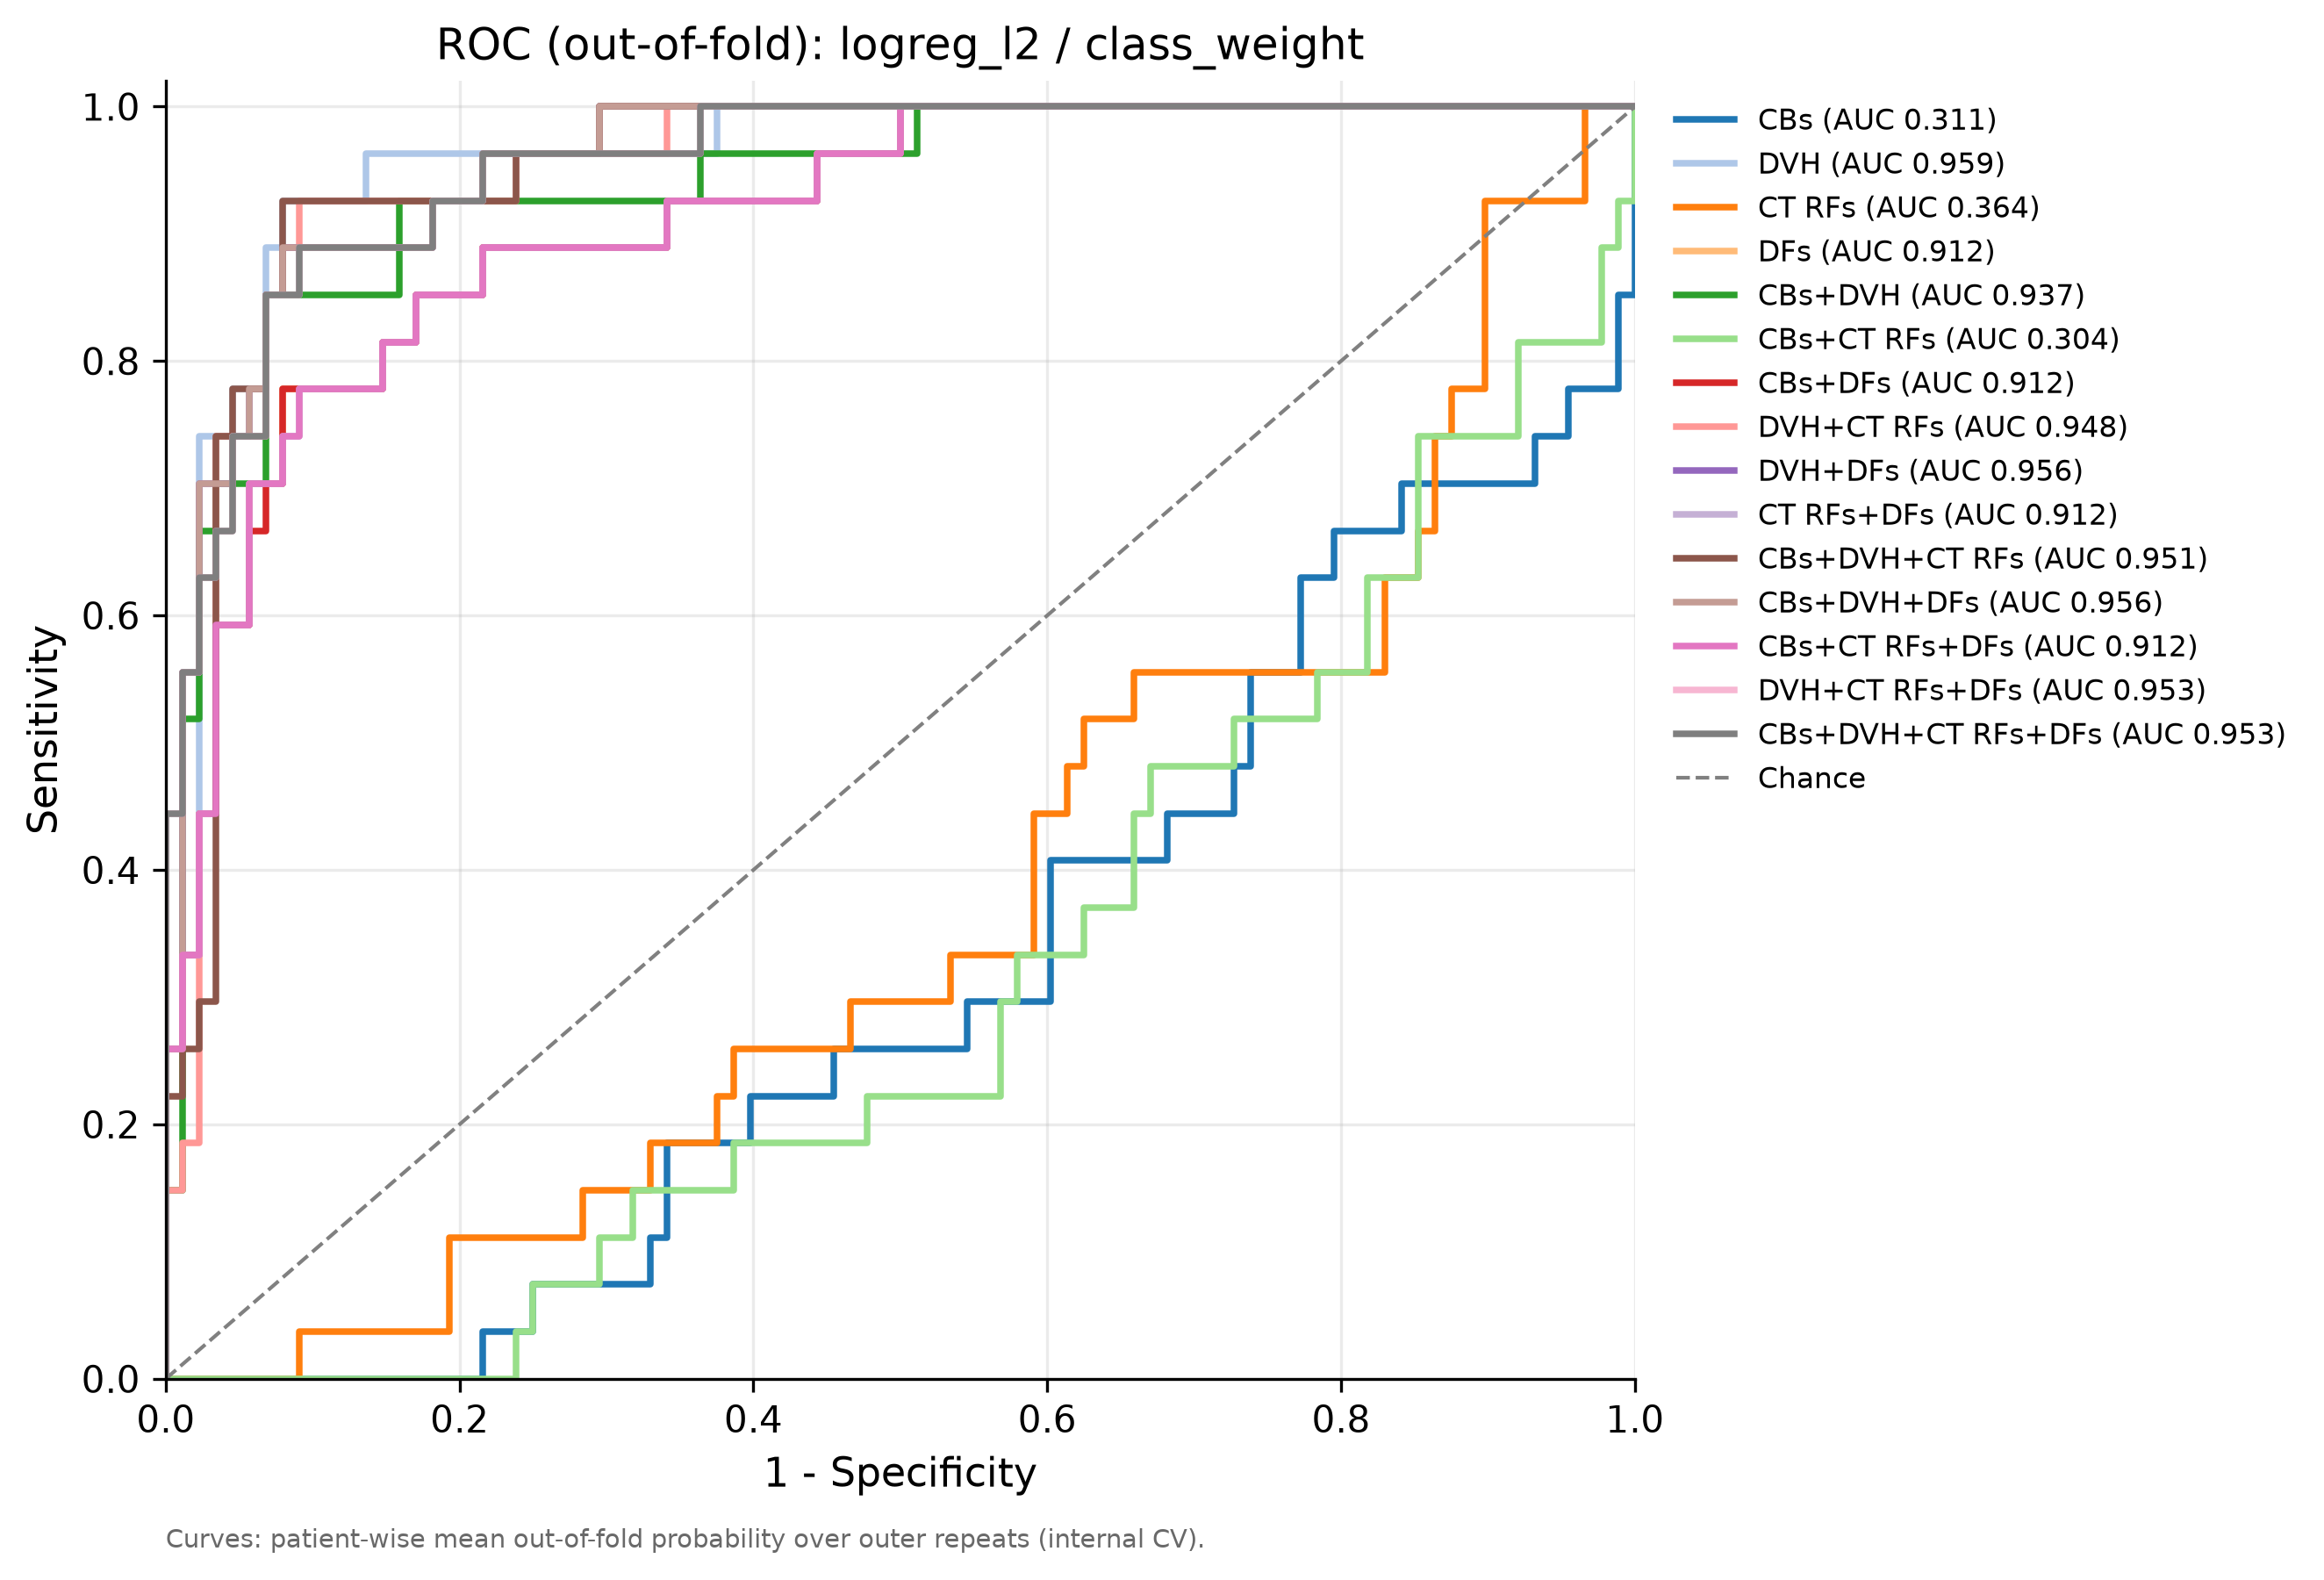

pr_all_configs_logreg_l2_class_weight.png


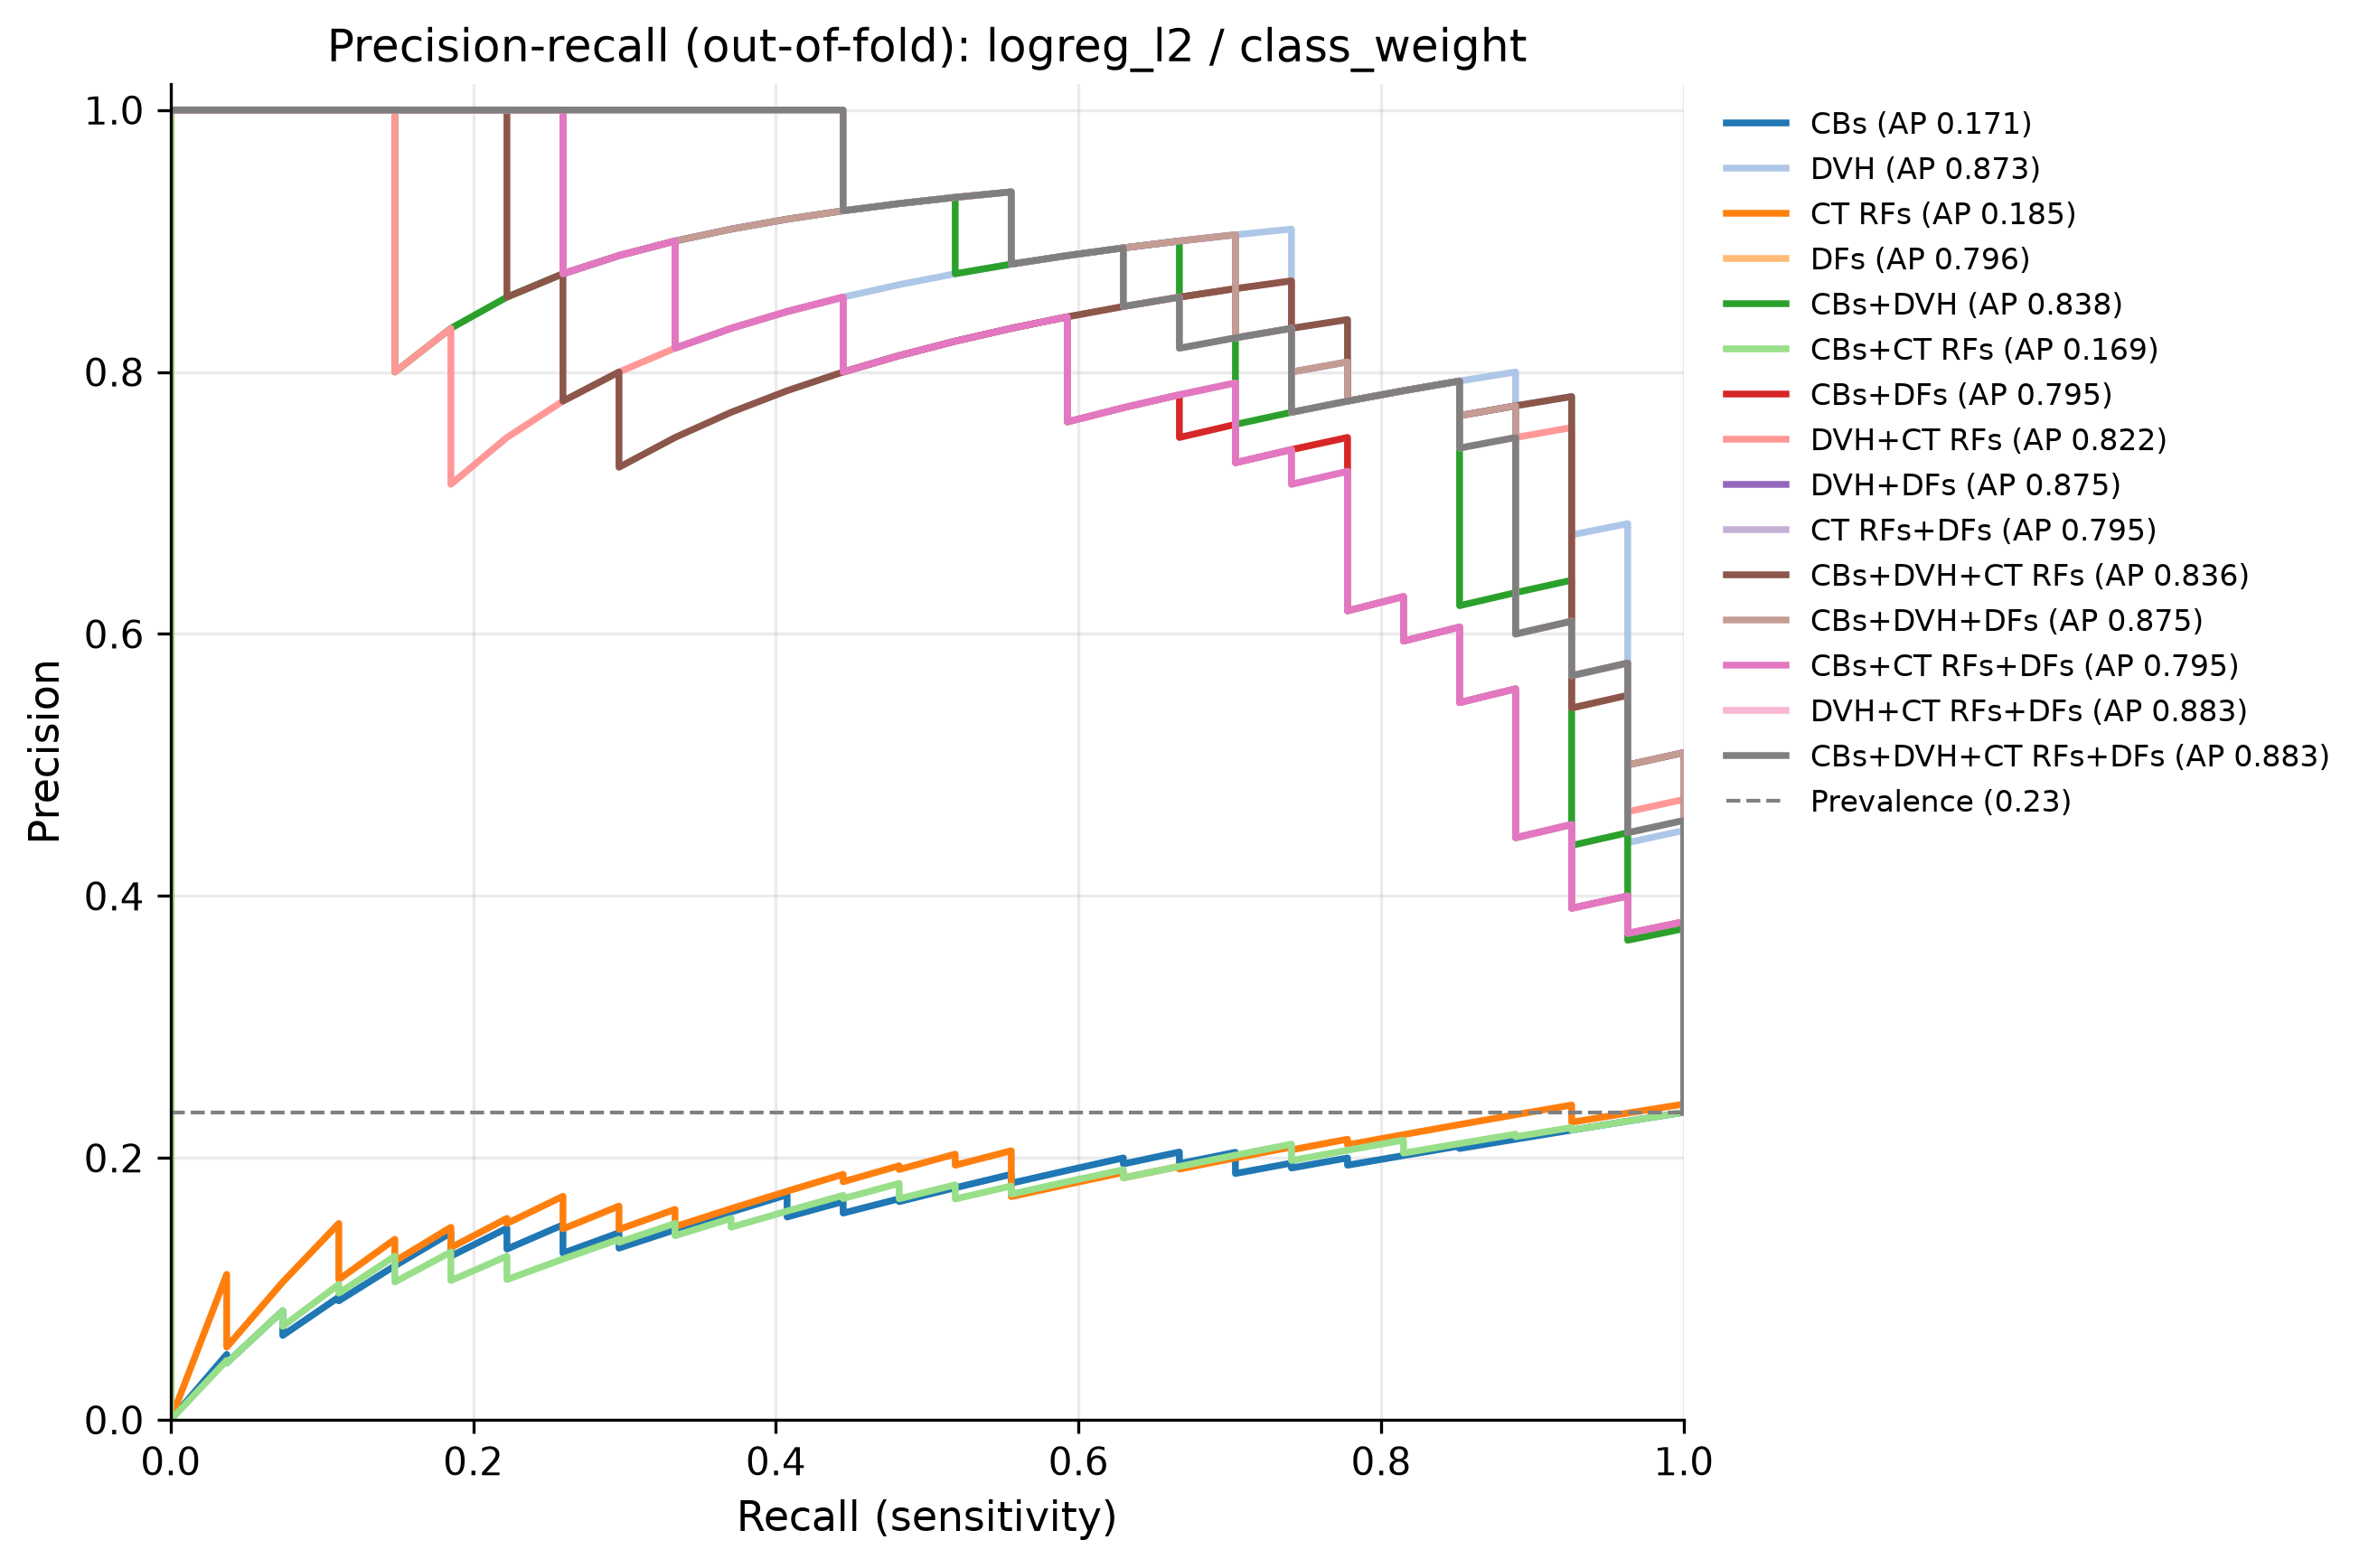

calibration_all_configs_logreg_l2_class_weight.png


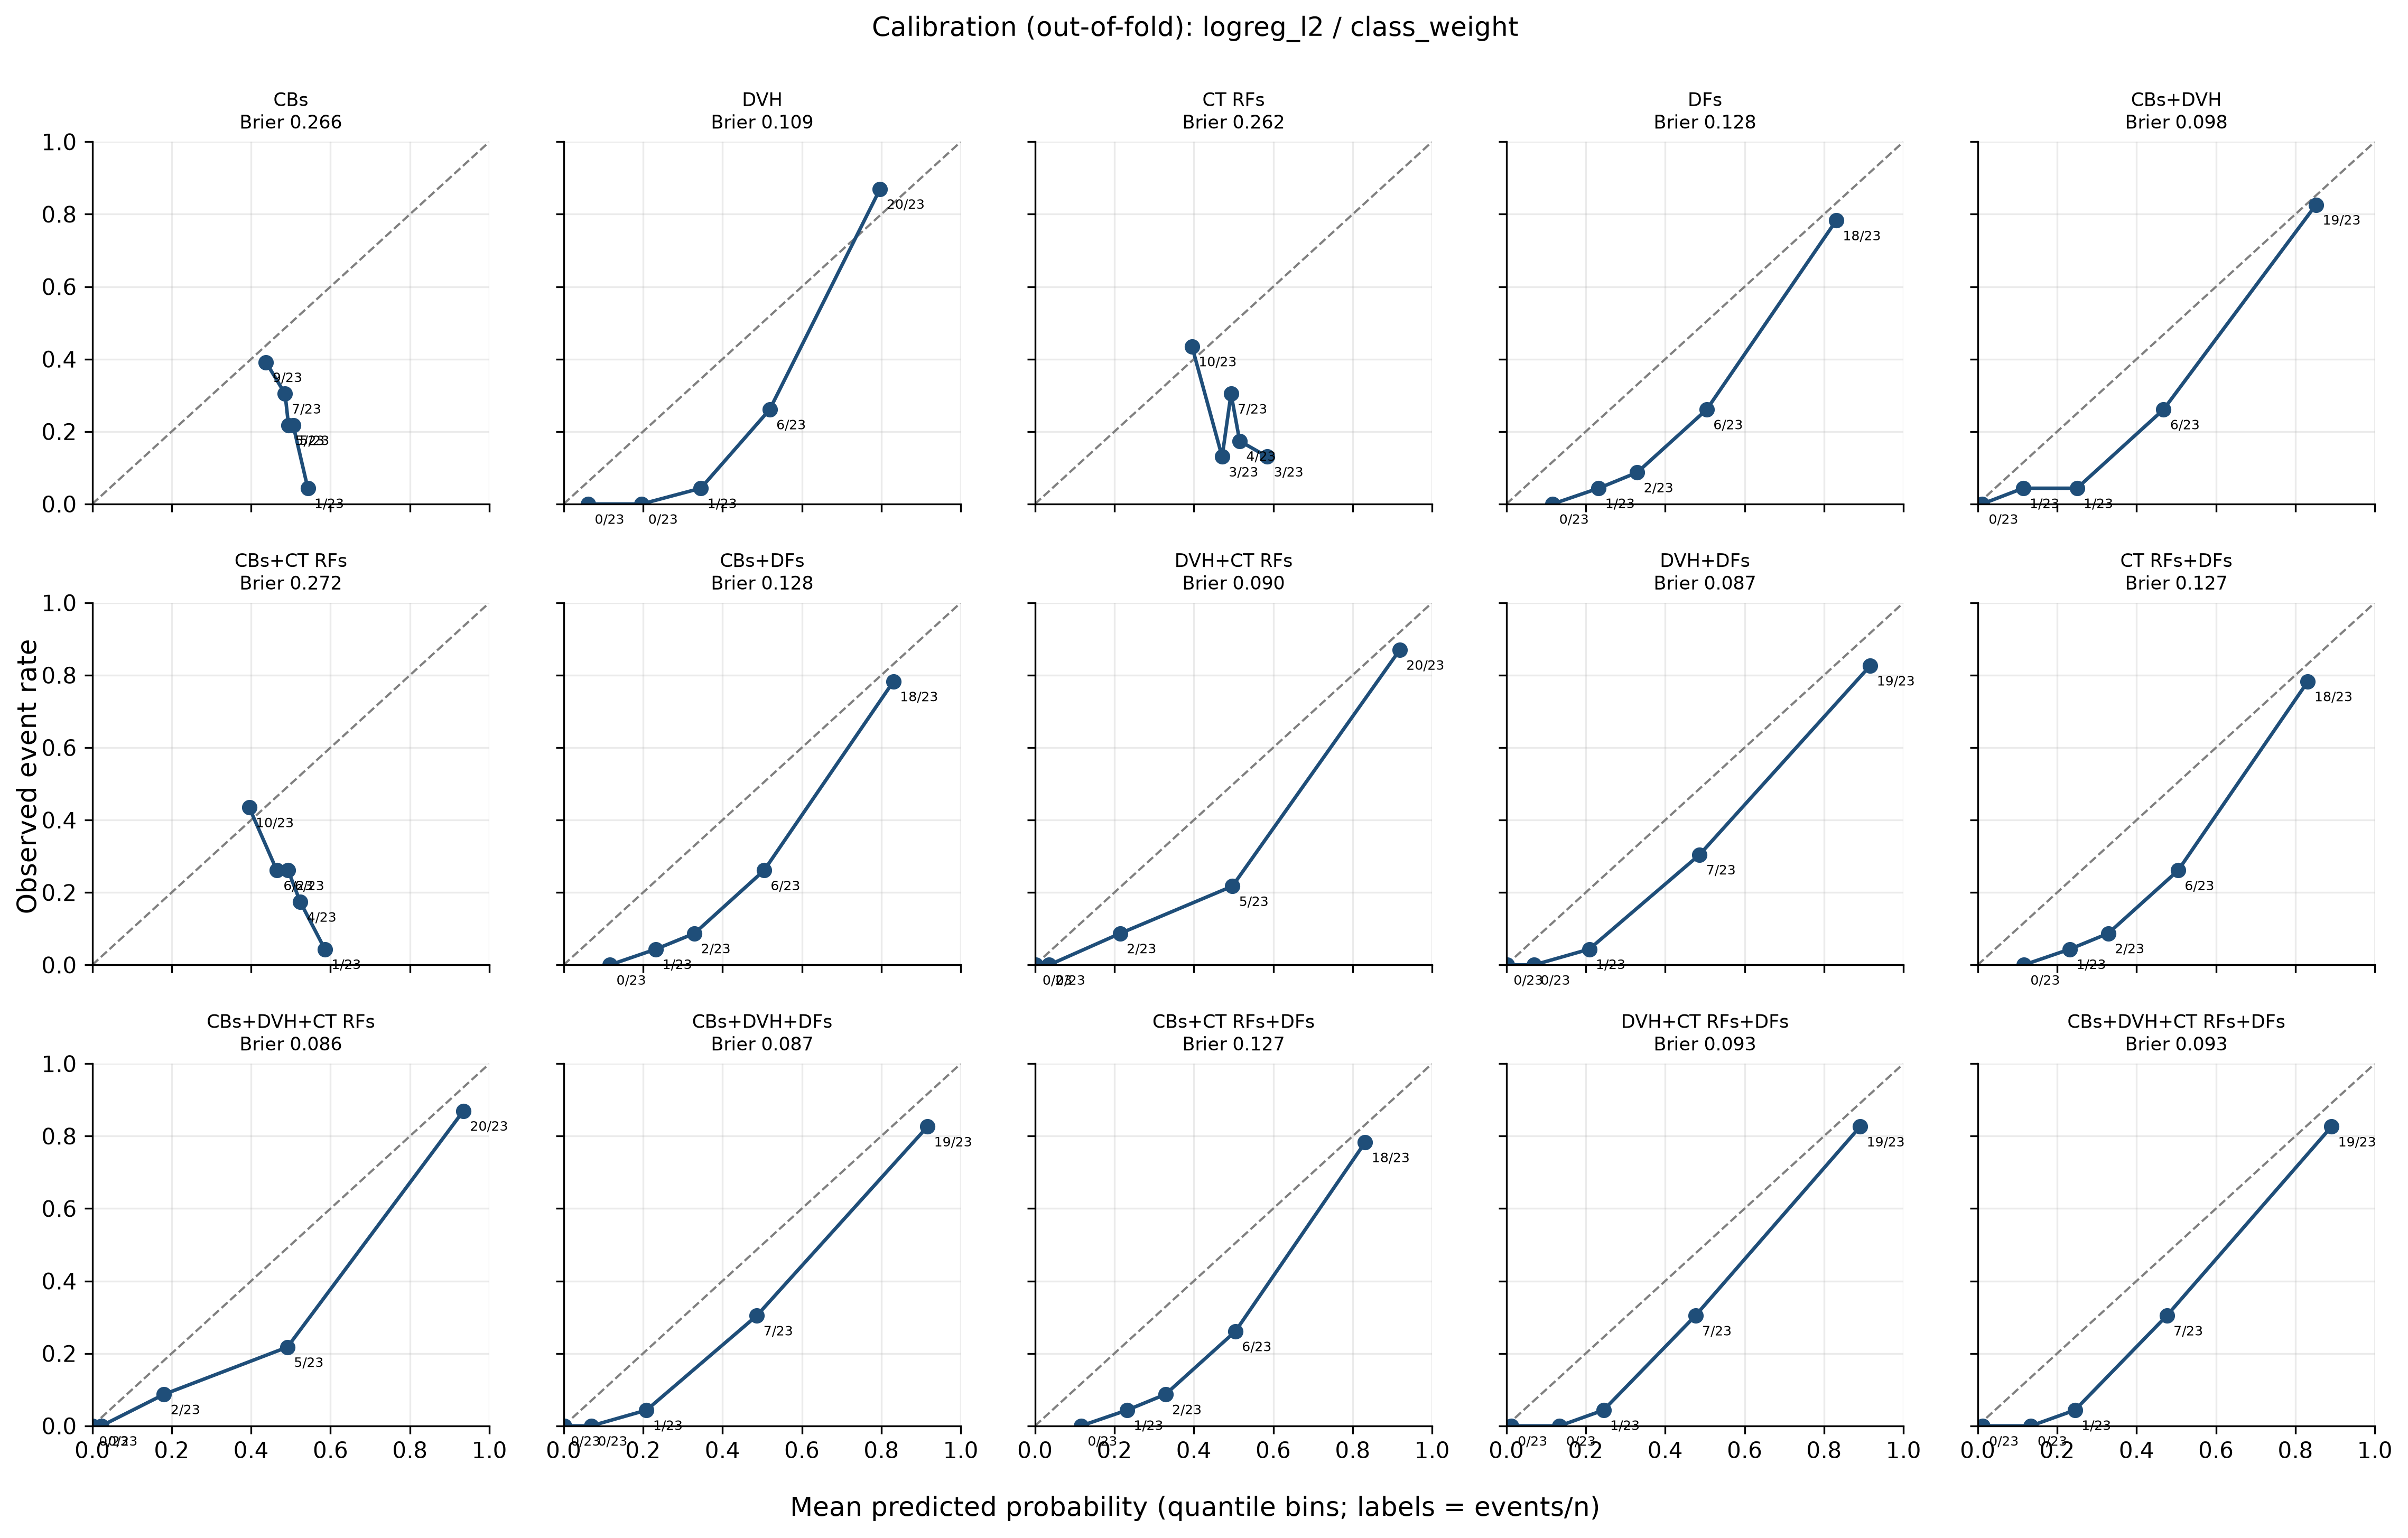

decision_curves_logreg_l2_class_weight.png


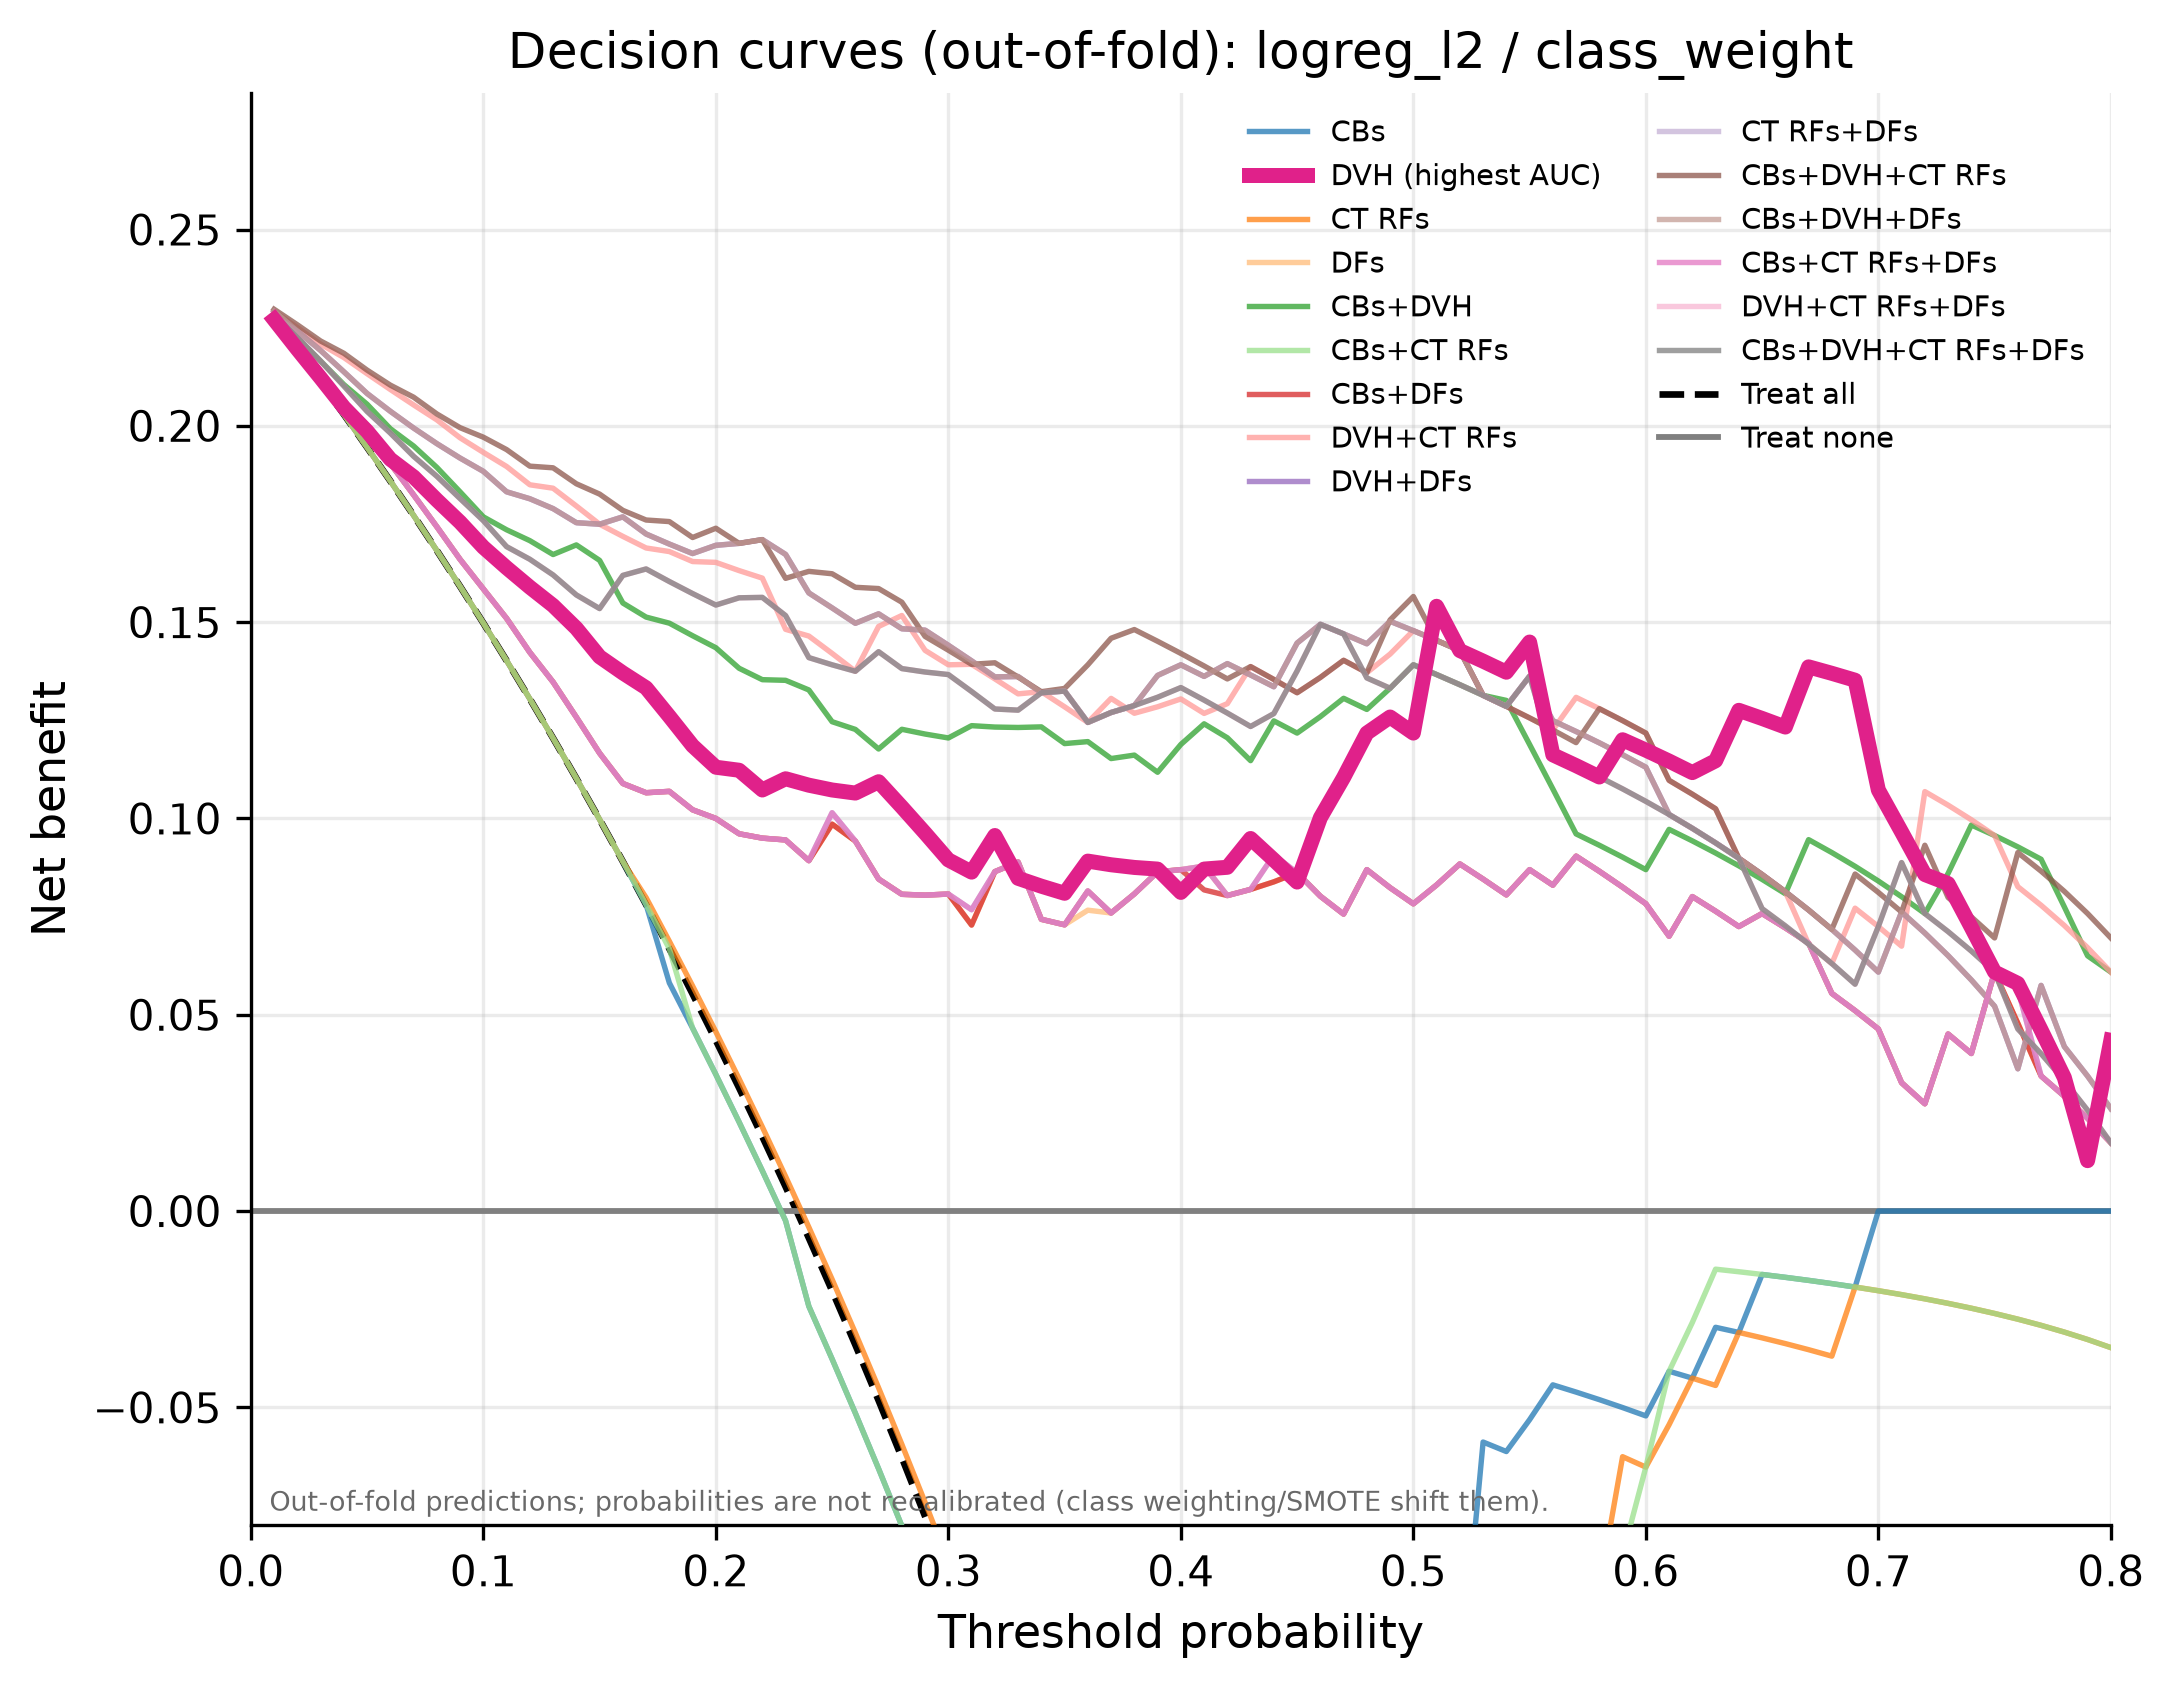

config_auc_ci_logreg_l2_class_weight.png


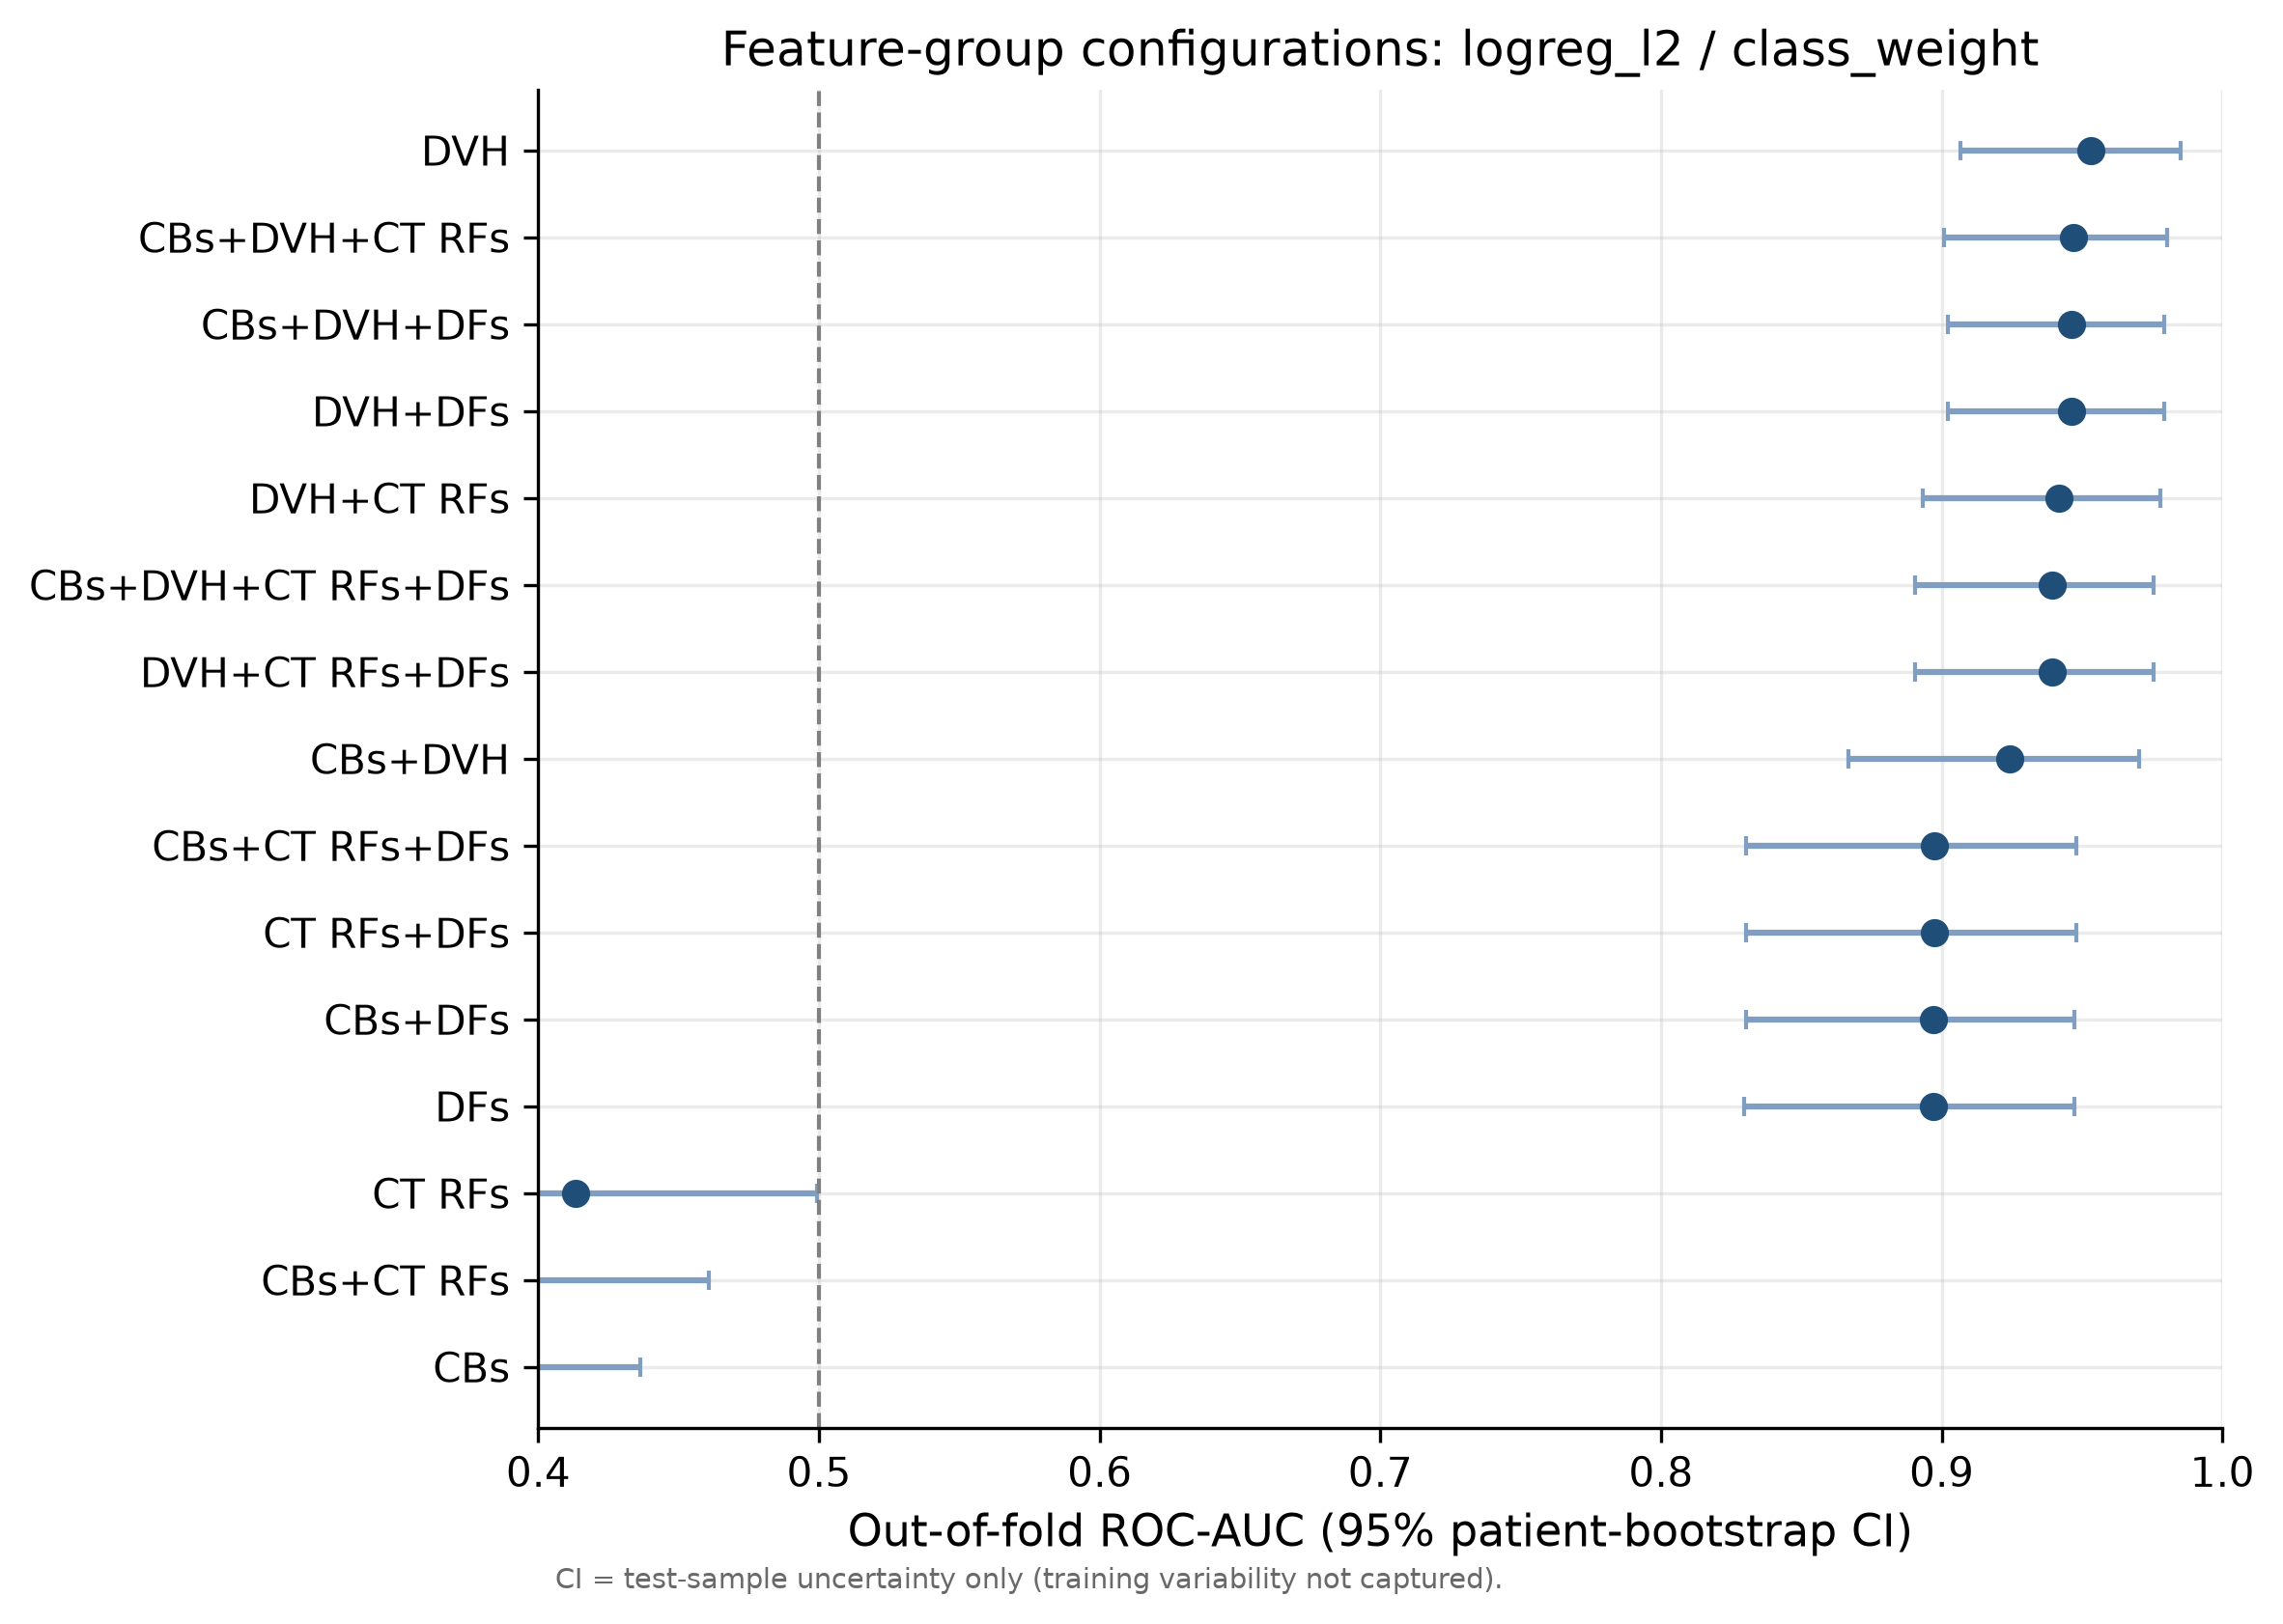

heatmap_auc_config_model_strategy.png


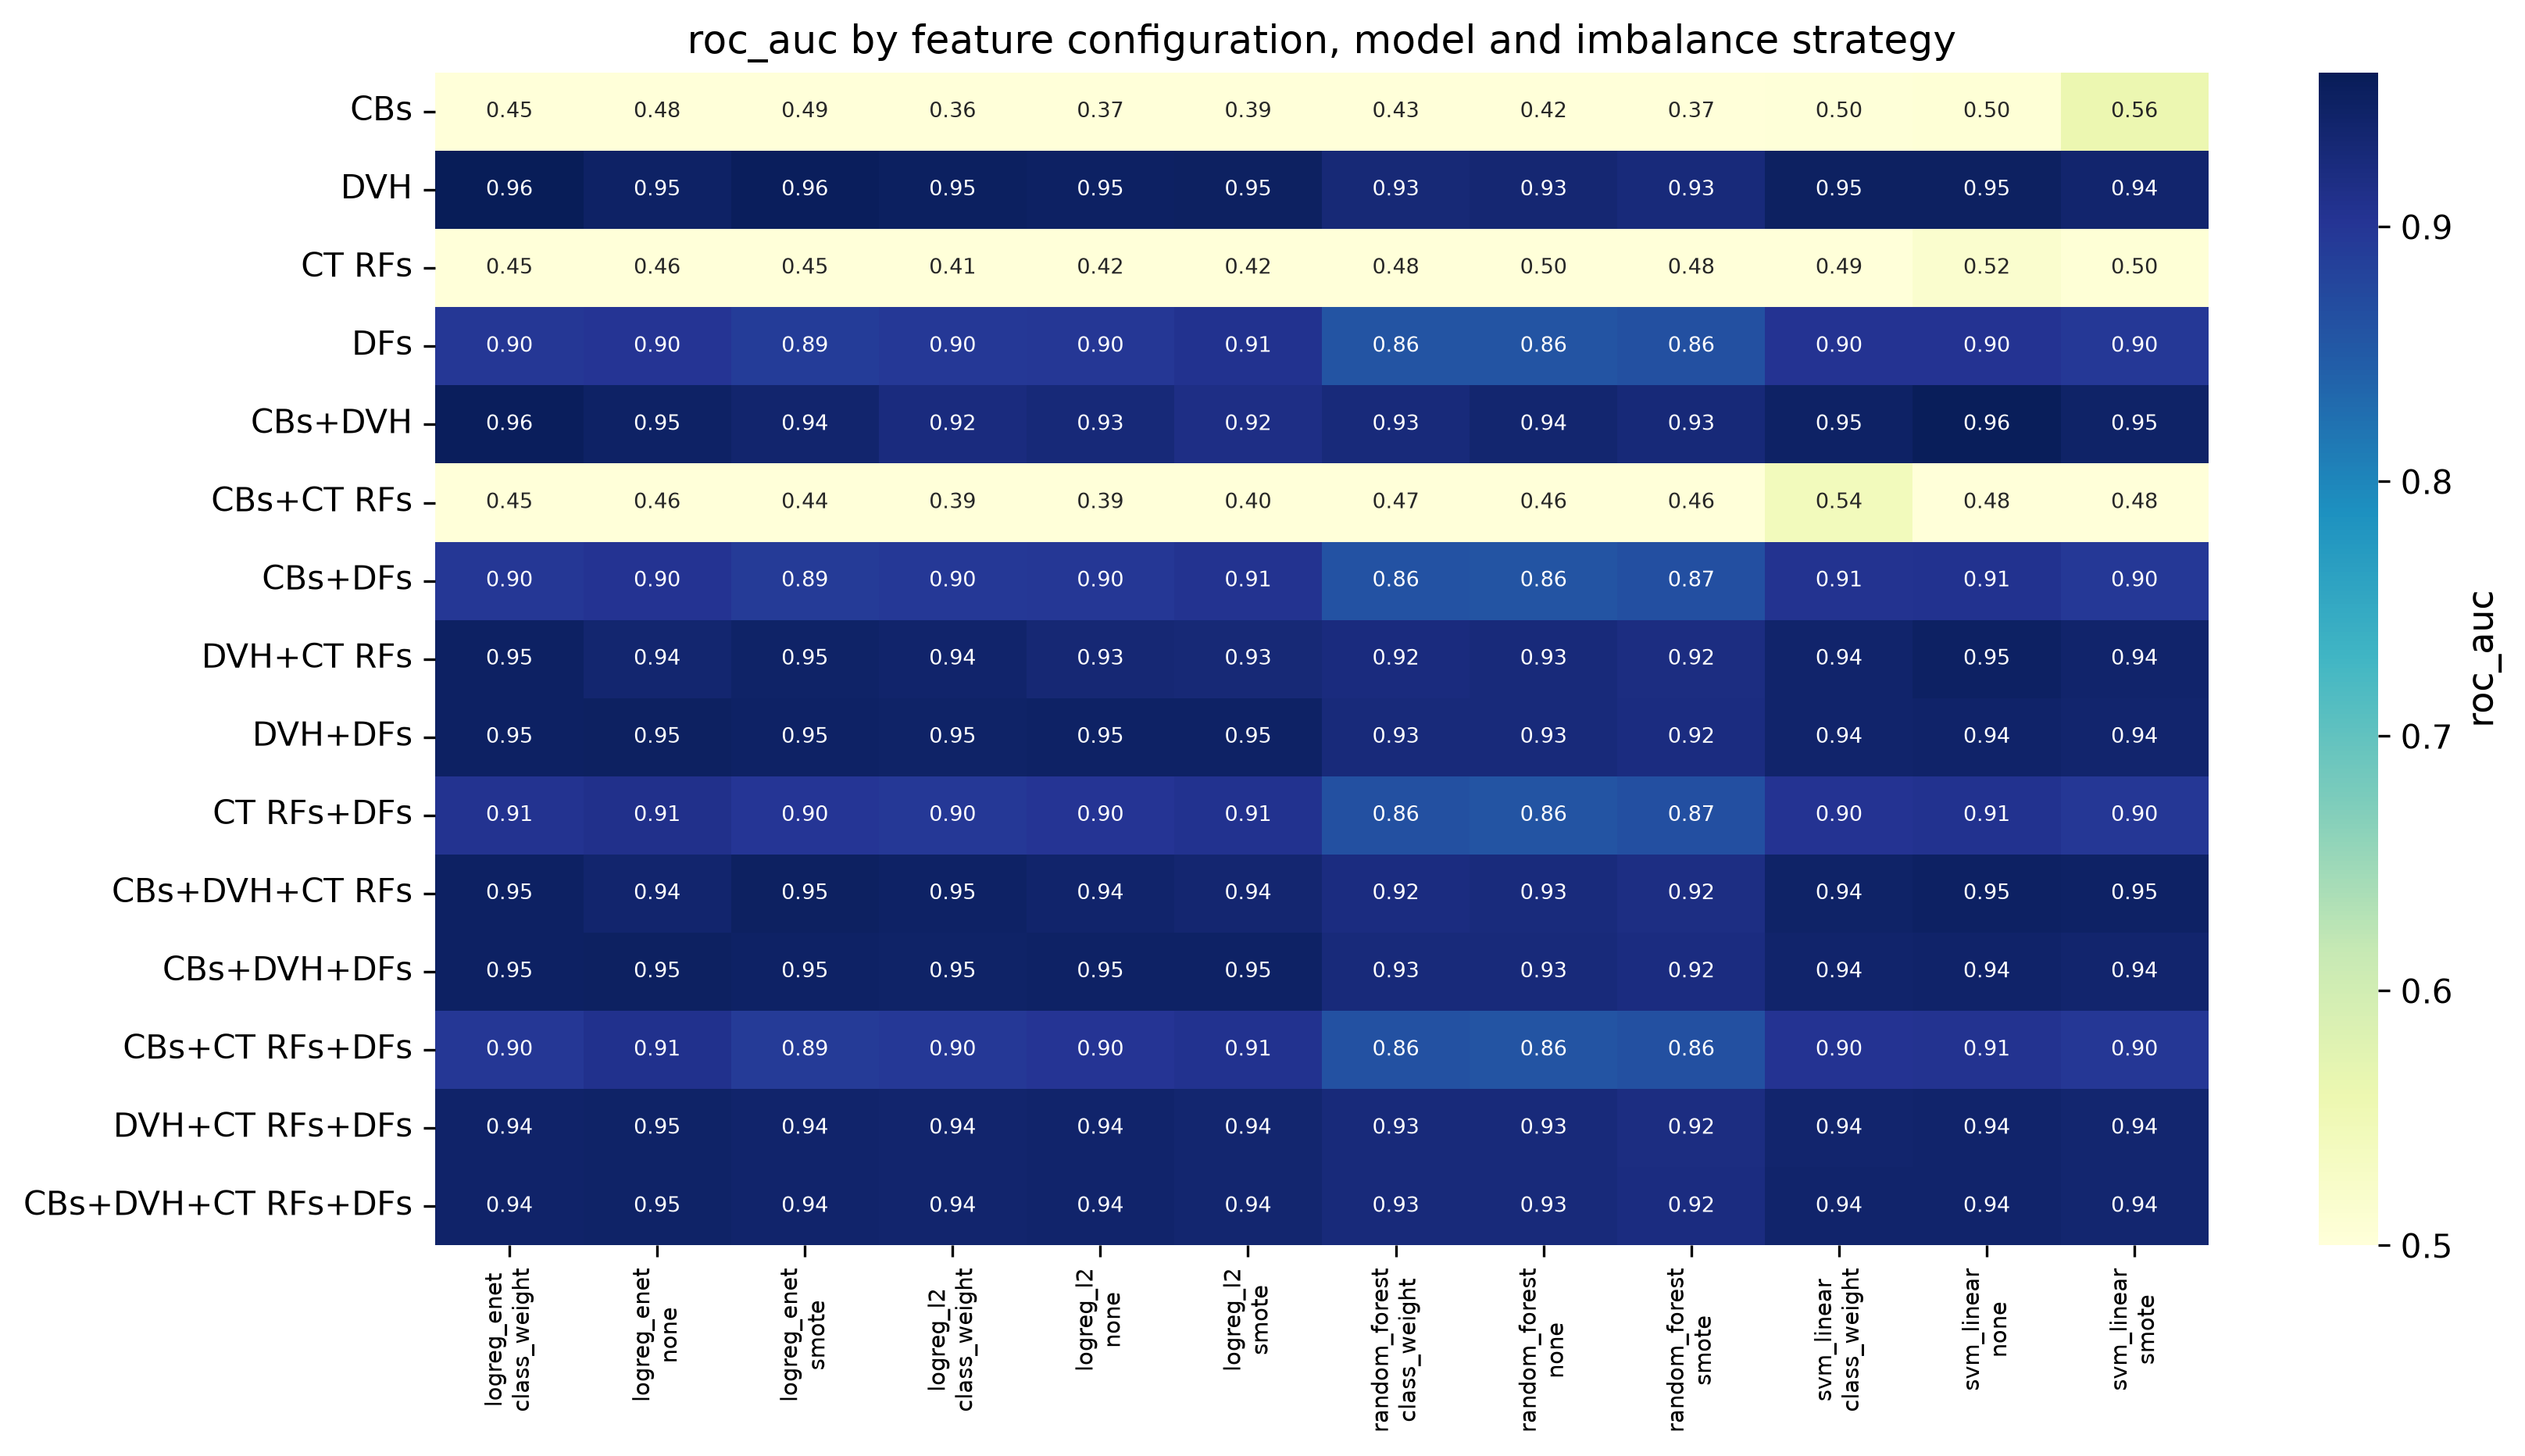

feature_selection_stability_heatmap.png


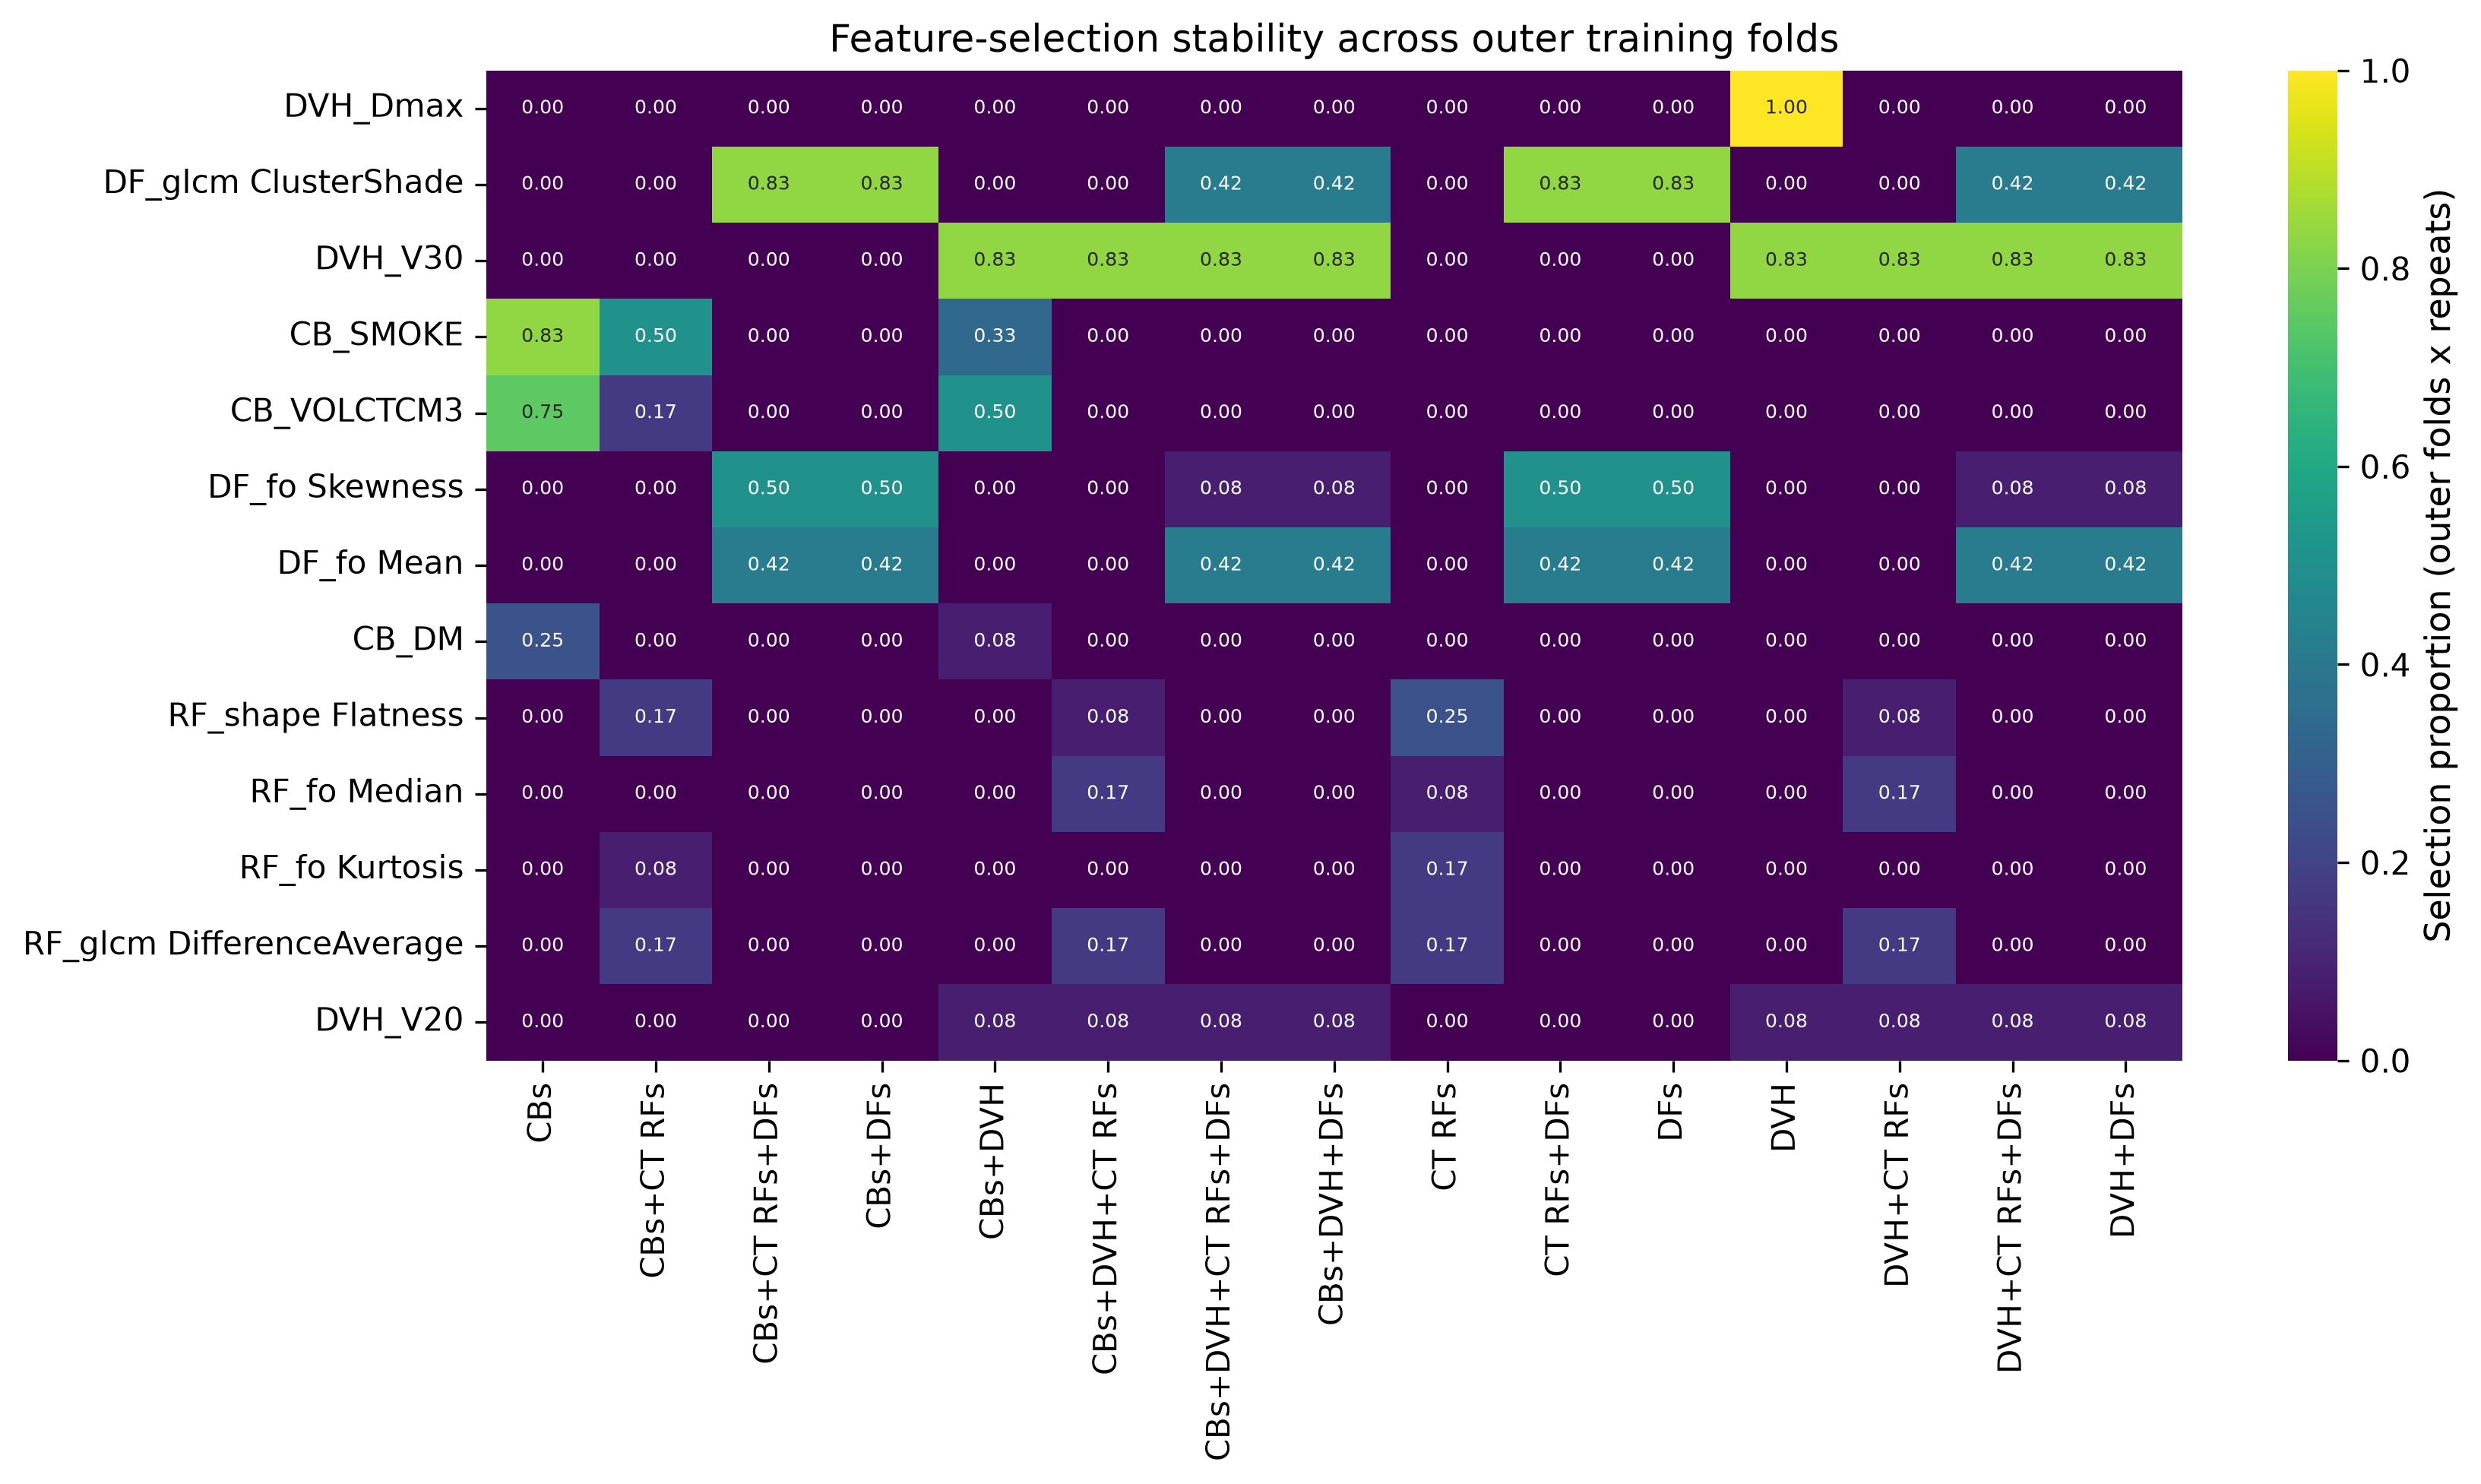

In [6]:
fig = RUN / 'figures'
for f in ['roc_all_configs_%s_%s.png' % (pm, ps), 'pr_all_configs_%s_%s.png' % (pm, ps),
          'calibration_all_configs_%s_%s.png' % (pm, ps), 'decision_curves_%s_%s.png' % (pm, ps),
          'config_auc_ci_%s_%s.png' % (pm, ps), 'heatmap_auc_config_model_strategy.png',
          'feature_selection_stability_heatmap.png']:
    if (fig / f).exists():
        print(f); display(Image(filename=str(fig / f), width=800))

## 6. Interpretation guardrails
* Confidence intervals are patient-bootstrap intervals of the out-of-fold predictions; they ignore variability of the training procedure and are optimistic.
* The configuration with the highest AUC is selected *after* looking at the same data – its AUC is optimistically biased.
* Pairwise comparisons are descriptive; no multiplicity-adjusted significance claim is supported.
* 27 events and 2–5 selected features: results are hypothesis-generating.